<a href="https://colab.research.google.com/github/Renyambar/Reny_MachineLearning/blob/main/JS08/JS08_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Import Library

In [1]:
!pip install -q hdbscan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

sns.set_theme(style="whitegrid")

##Memuat dataset Iris

In [3]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

df = X.copy()
df["Species"] = [iris.target_names[i] for i in y]

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Label asli:", iris.target_names)

display(df.head())

Jumlah data: 150
Jumlah fitur: 4
Label asli: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


##Standardisasi data

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Ukuran data setelah standardisasi:", X_scaled.shape)

Ukuran data setelah standardisasi: (150, 4)


##Membuat model HDBSCAN

In [5]:
model = hdbscan.HDBSCAN(
    min_cluster_size=10,
    min_samples=5,
    metric="euclidean",
    cluster_selection_method="eom"
)

cluster_labels = model.fit_predict(X_scaled)

df["Cluster"] = cluster_labels

display(df.head(10))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species,Cluster
0,5.1,3.5,1.4,0.2,setosa,1
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,1
3,4.6,3.1,1.5,0.2,setosa,1
4,5.0,3.6,1.4,0.2,setosa,1
5,5.4,3.9,1.7,0.4,setosa,1
6,4.6,3.4,1.4,0.3,setosa,1
7,5.0,3.4,1.5,0.2,setosa,1
8,4.4,2.9,1.4,0.2,setosa,1
9,4.9,3.1,1.5,0.1,setosa,1


##Menghitung jumlah cluster dan noise

In [6]:
unique_labels = set(cluster_labels)

# Noise (-1) tidak dihitung sebagai cluster
n_clusters = len(unique_labels - {-1})
n_noise = np.sum(cluster_labels == -1)
noise_percentage = n_noise / len(cluster_labels) * 100

print("Jumlah cluster terbentuk:", n_clusters)
print("Jumlah data noise:", n_noise)
print(f"Persentase noise: {noise_percentage:.2f}%")

print("\nJumlah anggota setiap cluster:")
display(
    df["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Jumlah Data")
    .to_frame()
)

Jumlah cluster terbentuk: 2
Jumlah data noise: 2
Persentase noise: 1.33%

Jumlah anggota setiap cluster:


,Jumlah Data
Cluster,
-1,2
0,99
1,49


##Reduksi dimensi menggunakan PCA

In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Total variasi yang dijelaskan PCA:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

Total variasi yang dijelaskan PCA: 95.81%


##Visualisasi hasil clustering HDBSCAN

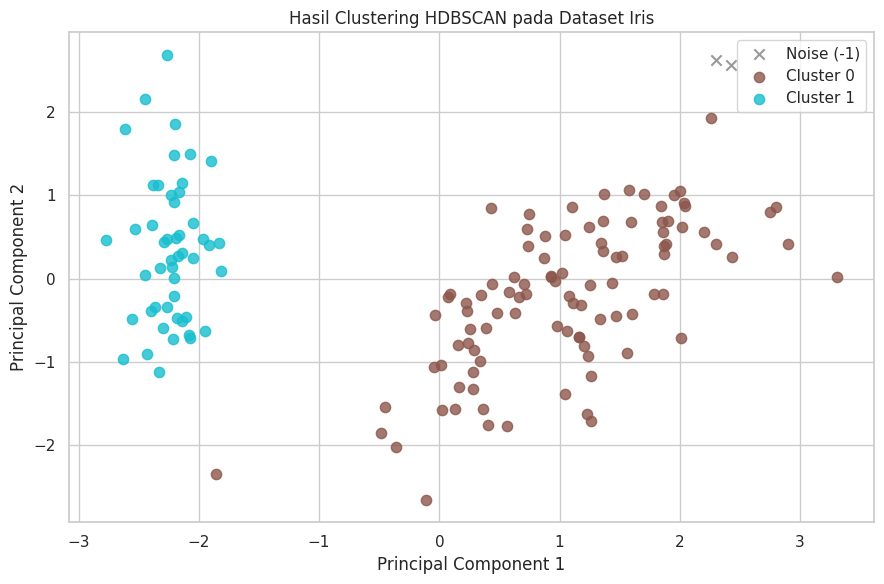

In [8]:
plt.figure(figsize=(9, 6))

unique_clusters = sorted(np.unique(cluster_labels))
colors = plt.cm.tab10(
    np.linspace(0, 1, max(len(unique_clusters), 1))
)

for cluster, color in zip(unique_clusters, colors):
    mask = cluster_labels == cluster

    if cluster == -1:
        label = "Noise (-1)"
        color = "gray"
        marker = "x"
    else:
        label = f"Cluster {cluster}"
        marker = "o"

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        color=color,
        label=label,
        marker=marker,
        alpha=0.8,
        s=55
    )

plt.title("Hasil Clustering HDBSCAN pada Dataset Iris")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

##Visualisasi label asli Iris

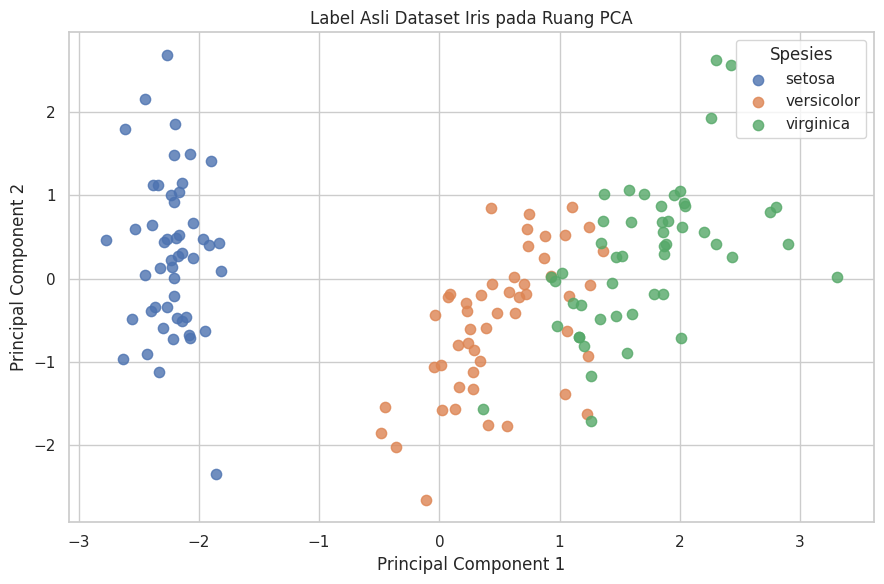

In [9]:
plt.figure(figsize=(9, 6))

for species_id, species_name in enumerate(iris.target_names):
    mask = y == species_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=species_name,
        alpha=0.8,
        s=55
    )

plt.title("Label Asli Dataset Iris pada Ruang PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Spesies")
plt.tight_layout()
plt.show()

##Membandingkan cluster dengan label asli

In [10]:
ari = adjusted_rand_score(y, cluster_labels)
nmi = normalized_mutual_info_score(y, cluster_labels)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")

print("\nTabel perbandingan label asli dan cluster:")
comparison = pd.crosstab(
    df["Species"],
    df["Cluster"],
    rownames=["Spesies Asli"],
    colnames=["Cluster HDBSCAN"]
)

display(comparison)

Adjusted Rand Index (ARI): 0.5394
Normalized Mutual Information (NMI): 0.6778

Tabel perbandingan label asli dan cluster:


Cluster HDBSCAN,-1,0,1
Spesies Asli,,,
setosa,0,1,49
versicolor,0,50,0
virginica,2,48,0


Analisis dan kesimpulan

In [11]:
print("ANALISIS HASIL HDBSCAN")
print("=" * 40)

print(f"Jumlah cluster: {n_clusters}")
print(f"Jumlah noise: {n_noise} dari {len(X)} data")
print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

if ari >= 0.75:
    print(
        "\nKesimpulan: hasil clustering memiliki kesesuaian "
        "yang kuat dengan label spesies asli."
    )
elif ari >= 0.4:
    print(
        "\nKesimpulan: hasil clustering memiliki kesesuaian "
        "sedang dengan label spesies asli."
    )
else:
    print(
        "\nKesimpulan: hasil clustering memiliki kesesuaian "
        "rendah dengan label spesies asli."
    )

if n_noise > 0:
    print(
        f"Ada {n_noise} data yang dianggap noise "
        "karena tidak masuk ke cluster yang cukup padat."
    )
else:
    print("Tidak ada data yang dikategorikan sebagai noise.")

print(
    "\nCatatan: HDBSCAN mengelompokkan data berdasarkan kepadatan, "
    "bukan berdasarkan label spesies. Perbedaan hasil dengan label "
    "asli tidak selalu berarti algoritma gagal."
)

ANALISIS HASIL HDBSCAN
Jumlah cluster: 2
Jumlah noise: 2 dari 150 data
ARI: 0.5394
NMI: 0.6778

Kesimpulan: hasil clustering memiliki kesesuaian sedang dengan label spesies asli.
Ada 2 data yang dianggap noise karena tidak masuk ke cluster yang cukup padat.

Catatan: HDBSCAN mengelompokkan data berdasarkan kepadatan, bukan berdasarkan label spesies. Perbedaan hasil dengan label asli tidak selalu berarti algoritma gagal.


Pada praktikum ini, algoritma HDBSCAN diterapkan pada dataset Iris dengan menggunakan empat fitur numerik yang telah distandardisasi. PCA digunakan untuk memproyeksikan data ke dalam dua dimensi sehingga pola pengelompokan dapat divisualisasikan.

Hasil clustering menghasilkan 2 cluster dan 2 data noise. Kesesuaian dengan label spesies asli dianalisis menggunakan ARI sebesar 0.5394 dan NMI sebesar 0.6778.

HDBSCAN mengelompokkan data berdasarkan kepadatan dan kestabilan cluster, sedangkan label asli Iris menunjukkan spesies bunga. Oleh karena itu, hasil clustering belum tentu sama persis dengan tiga spesies asli. Visualisasi PCA dan tabel perbandingan label digunakan untuk mengetahui spesies mana yang cenderung tergabung dalam cluster yang sama.